# 09 · Analysis: metrics, significance, files and diagrams

Plan section 6. Reads every run in `results/runs/` (v1, and v2 once it exists) and writes:

* `results/run_metrics.parquet` (`run_id, index, level, metric, value, subset, n, ci_lo, ci_hi`) and `results/question_metrics.parquet` (per question, for the paired tests);
* `results/units/metrics.{csv,xlsx}` and `results/win500/metrics.{csv,xlsx}`: **one table per index**, to be merged by hand later;
* `results/granularity.csv`: RQ7, windows vs units;
* `results/diagrams/<run_id>.md`: Mermaid pipeline diagrams of hand-picked runs.

**n = 92 answerable; 8 unanswerable excluded** in every metric table. Tables are sorted by section-level nDCG@10 for readability only: every metric is reported and read, and no run is selected as the winner.

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)  # all paths below are relative to the repo root
from dotenv import load_dotenv
load_dotenv(ROOT / ".env")
DATA = ROOT / "data"
RESULTS = ROOT / "results"

In [2]:
import json
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from tqdm.auto import tqdm
from csrag import evaluate as ev, report as rp, runs
from csrag.corpus import Corpus
from csrag.retrievers.base import EXPANSION_METHODS, RANKED_METHODS

corpus = Corpus(DATA)
questions, problems = ev.load_questions(DATA / "eval" / "questions.jsonl", corpus)
qrels = ev.read_qrels(DATA / "eval" / "qrels.jsonl")
run_ids = runs.list_runs()
rt = ev.run_table(run_ids)
rt.groupby(["params_version", "index", "gate"]).size().rename("runs").to_frame().T

params_version    v1                   
index          units       win500      
gate           False True   False True 
runs              26    29     26    29

## Evaluate every run

In [3]:
pq, rm, gates, costs = ev.evaluate_all(run_ids, questions, qrels, corpus, progress=tqdm)
gate_overall = ev.gate_loss_vs_gate_off(pq, rt)
RESULTS.mkdir(exist_ok=True)
rm.to_parquet(RESULTS / "run_metrics.parquet", index=False)
pq.to_parquet(RESULTS / "question_metrics.parquet", index=False)
# first_gold_rank is NaN when the gold is not retrieved, so it is the one metric with n < 92
scored = rm[(rm["subset"] == "all") & rm["level"].isin(["unit", "section", "group", "evidence"]) & (rm["metric"] != "first_gold_rank")]
assert (scored["n"] == 92).all(), "every scored metric row must have n = 92"
print(len(rm), "metric rows for", rm["run_id"].nunique(), "runs; n = 92 answerable, 8 unanswerable excluded")

evaluate:   0%|          | 0/110 [00:00<?, ?it/s]

17270 metric rows for 110 runs; n = 92 answerable, 8 unanswerable excluded


## Significance (pre-declared comparisons only)

Paired randomisation tests (sign flip, 10,000 permutations) on every metric. Holm correction within each RQ, metric and index (and params version). RQ1–RQ6 are tested within each index with matched gate and budget; RQ7 compares the two indexes with the gate off, at section/group level and on evidence recall. Everything else is descriptive.

In [4]:
qids = [q["question_id"] for q in questions if q["answerable"]]
sig = pd.concat([ev.significance(pq, rt, qids, index=i) for i in corpus.indexes()], ignore_index=True)
sig7 = ev.significance(pq, rt, qids, rq7=True)
key = (sig["level"] == "section") & (sig["metric"] == "ndcg@10")
sig[key][["rq", "a", "b", "index", "gate", "budget", "params_version", "mean_a", "mean_b", "diff", "diff_ci_lo",
          "diff_ci_hi", "p", "p_holm"]].round(4)

,rq,a,b,index,gate,budget,params_version,mean_a,mean_b,diff,diff_ci_lo,diff_ci_hi,p,p_holm
24,RQ1,S1,L1,units,False,NaN,v1,0.8230,0.8460,-0.0229,-0.0627,0.0146,0.2652,1.0000
69,RQ1,S1,L1,units,True,NaN,v1,0.8054,0.8337,-0.0283,-0.0730,0.0132,0.2172,1.0000
114,RQ1,D1,L1,units,False,NaN,v1,0.8482,0.8460,0.0023,-0.0483,0.0535,0.9318,1.0000
159,RQ1,D1,L1,units,True,NaN,v1,0.8279,0.8337,-0.0057,-0.0614,0.0492,0.8438,1.0000
204,RQ1,C1,L1,units,False,NaN,v1,0.8627,0.8460,0.0167,-0.0267,0.0608,0.4655,1.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4209,RQ6,T2+T3,T0,win500,False,8192.0,v1,0.8975,0.8658,0.0318,0.0062,0.0574,0.0176,0.2640
4254,RQ6,T2+T3,T0,win500,True,8192.0,v1,0.9008,0.8650,0.0358,0.0112,0.0610,0.0074,0.1184
4299,RQ6,T4,T2+T3,win500,True,16384.0,v1,0.9078,0.8995,0.0083,-0.0295,0.0480,0.6809,1.0000
4344,RQ6,T4,T2+T3,win500,True,4096.0,v1,0.9048,0.8954,0.0094,-0.0310,0.0508,0.6657,1.0000


## Write the metrics files

In [5]:
written = {i: rp.write_index_files(i, rm, pq, rt, gates, costs, gate_overall, sig, questions, corpus) for i in corpus.indexes()}
rp.write_granularity(sig7, RESULTS / "granularity.csv")
written

{'units': {'csv': PosixPath('results/units/metrics.csv'),
  'xlsx': PosixPath('results/units/metrics.xlsx'),
  'runs': 55},
 'win500': {'csv': PosixPath('results/win500/metrics.csv'),
  'xlsx': PosixPath('results/win500/metrics.xlsx'),
  'runs': 55}}

## Tables by research question

Key columns only; the CSV/XLSX files hold every metric.

In [6]:
tables = {i: pd.read_csv(RESULTS / i / "metrics.csv") for i in corpus.indexes()}
COLS = ["method", "gate", "budget", "section_ndcg@10", "section_ndcg@10_ci_lo", "section_ndcg@10_ci_hi",
        "section_recall@10", "section_mrr@10", "evidence_recall@10", "unit_ndcg@10", "latency_total_s"]

def rq_table(methods, index, params_version="v1", extra=()):
    t = tables[index]
    t = t[t["method"].isin(methods) & (t["params_version"] == params_version)]
    cols = [c for c in COLS + list(extra) if c in t.columns]
    return t[cols].sort_values(["method", "gate", "budget"]).round(3)

RQ = {
    "RQ1 single signals": ["L1", "S1", "D1", "C1"],
    "RQ2 hybrid and multi-stage": ["L1", "D1", "H1", "H2", "M1"],
    "RQ3 rerankers": ["H1", "X1", "X2"],
    "RQ4 LLM query rewrites": ["L1", "D1", "Q1", "Q2"],
    "RQ5 metadata and structure": ["H1", "F0", "F1", "T1"],
}
for name, methods in RQ.items():
    for index in corpus.indexes():
        display(Markdown(f"### {name} · `{index}`"))
        display(rq_table(methods, index))

### RQ1 single signals · `units`

,method,gate,budget,section_ndcg@10,section_ndcg@10_ci_lo,section_ndcg@10_ci_hi,section_recall@10,section_mrr@10,evidence_recall@10,unit_ndcg@10,latency_total_s
39,C1,False,NaN,0.863,0.823,0.900,0.989,0.892,0.989,0.902,1.898
46,C1,True,NaN,0.847,0.806,0.887,0.989,0.892,0.989,0.900,1.898
45,D1,False,NaN,0.848,0.802,0.891,0.989,0.882,0.967,0.889,0.034
50,D1,True,NaN,0.828,0.777,0.875,0.967,0.879,0.967,0.886,0.034
47,L1,False,NaN,0.846,0.800,0.888,0.978,0.894,0.978,0.903,0.035
48,L1,True,NaN,0.834,0.785,0.878,0.967,0.893,0.967,0.891,0.035
51,S1,False,NaN,0.823,0.779,0.865,0.989,0.855,0.989,0.859,0.034
52,S1,True,NaN,0.805,0.757,0.851,0.978,0.853,0.978,0.852,0.034


### RQ1 single signals · `win500`

,method,gate,budget,section_ndcg@10,section_ndcg@10_ci_lo,section_ndcg@10_ci_hi,section_recall@10,section_mrr@10,evidence_recall@10,unit_ndcg@10,latency_total_s
23,C1,False,NaN,0.880,0.845,0.913,1.000,0.935,1.000,0.907,1.442
44,C1,True,NaN,0.861,0.823,0.896,1.000,0.935,0.989,0.901,1.442
45,D1,False,NaN,0.856,0.814,0.896,0.989,0.896,0.978,0.866,0.034
51,D1,True,NaN,0.835,0.787,0.880,0.967,0.893,0.957,0.860,0.034
46,L1,False,NaN,0.852,0.808,0.893,0.978,0.905,0.978,0.879,0.036
50,L1,True,NaN,0.840,0.793,0.883,0.967,0.903,0.967,0.864,0.036
48,S1,False,NaN,0.845,0.804,0.884,0.989,0.881,0.978,0.854,0.034
52,S1,True,NaN,0.827,0.783,0.868,0.989,0.881,0.978,0.847,0.034


### RQ2 hybrid and multi-stage · `units`

,method,gate,budget,section_ndcg@10,section_ndcg@10_ci_lo,section_ndcg@10_ci_hi,section_recall@10,section_mrr@10,evidence_recall@10,unit_ndcg@10,latency_total_s
45,D1,False,NaN,0.848,0.802,0.891,0.989,0.882,0.967,0.889,0.034
50,D1,True,NaN,0.828,0.777,0.875,0.967,0.879,0.967,0.886,0.034
29,H1,False,NaN,0.870,0.830,0.908,1.000,0.928,0.989,0.928,0.038
25,H1,True,NaN,0.876,0.840,0.911,1.000,0.943,1.000,0.938,0.038
33,H2,False,NaN,0.868,0.830,0.904,1.000,0.907,1.000,0.913,0.040
34,H2,True,NaN,0.867,0.830,0.902,1.000,0.918,1.000,0.921,0.040
47,L1,False,NaN,0.846,0.800,0.888,0.978,0.894,0.978,0.903,0.035
48,L1,True,NaN,0.834,0.785,0.878,0.967,0.893,0.967,0.891,0.035
38,M1,False,NaN,0.863,0.823,0.900,0.989,0.892,0.989,0.902,0.168
49,M1,True,NaN,0.833,0.783,0.879,0.967,0.881,0.967,0.890,0.048


... (10 outputs left out)

### RQ5 metadata and structure · `units`

,method,gate,budget,section_ndcg@10,section_ndcg@10_ci_lo,section_ndcg@10_ci_hi,section_recall@10,section_mrr@10,evidence_recall@10,unit_ndcg@10,latency_total_s
22,F0,False,NaN,0.877,0.838,0.913,1.0,0.929,0.989,0.929,0.036
20,F0,True,NaN,0.881,0.847,0.914,1.0,0.948,1.000,0.943,0.036
21,F1,False,NaN,0.878,0.839,0.914,1.0,0.929,0.989,0.929,0.994
19,F1,True,NaN,0.882,0.847,0.915,1.0,0.948,1.000,0.943,0.994
29,H1,False,NaN,0.870,0.830,0.908,1.0,0.928,0.989,0.928,0.038
25,H1,True,NaN,0.876,0.840,0.911,1.0,0.943,1.000,0.938,0.038
31,T1,False,NaN,0.870,0.830,0.908,1.0,0.928,0.989,0.928,0.038
24,T1,True,NaN,0.876,0.840,0.911,1.0,0.943,1.000,0.938,0.038


### RQ5 metadata and structure · `win500`

,method,gate,budget,section_ndcg@10,section_ndcg@10_ci_lo,section_ndcg@10_ci_hi,section_recall@10,section_mrr@10,evidence_recall@10,unit_ndcg@10,latency_total_s
22,F0,False,NaN,0.881,0.845,0.914,1.0,0.917,1.0,0.904,0.035
26,F0,True,NaN,0.871,0.837,0.904,1.0,0.916,1.0,0.896,0.035
19,F1,False,NaN,0.885,0.849,0.917,1.0,0.922,1.0,0.907,0.993
25,F1,True,NaN,0.875,0.841,0.907,1.0,0.921,1.0,0.899,0.993
31,H1,False,NaN,0.866,0.829,0.900,1.0,0.911,1.0,0.899,0.038
34,H1,True,NaN,0.865,0.830,0.899,1.0,0.910,1.0,0.889,0.038
32,T1,False,NaN,0.866,0.829,0.900,1.0,0.911,1.0,0.899,0.038
39,T1,True,NaN,0.865,0.830,0.899,1.0,0.910,1.0,0.889,0.038


In [7]:
for index in corpus.indexes():
    display(Markdown(f"### RQ6 expansion · `{index}`"))
    display(rq_table(EXPANSION_METHODS, index, extra=("evidence_recall@ctx", "context_tokens", "llm_calls")))

### RQ6 expansion · `units`

,method,gate,budget,section_ndcg@10,section_ndcg@10_ci_lo,section_ndcg@10_ci_hi,section_recall@10,section_mrr@10,evidence_recall@10,unit_ndcg@10,latency_total_s,evidence_recall@ctx,context_tokens,llm_calls
42,T0,False,4096.0,0.856,0.810,0.899,0.978,0.925,0.978,0.915,0.038,0.978,4065.32,0.00
35,T0,False,8192.0,0.866,0.825,0.905,1.000,0.928,0.989,0.929,0.038,1.000,8161.48,0.00
30,T0,False,16384.0,0.870,0.830,0.908,1.000,0.928,0.989,0.928,0.038,1.000,16347.50,0.00
36,T0,True,4096.0,0.865,0.823,0.903,0.989,0.939,0.989,0.925,0.038,0.989,3665.97,0.00
23,T0,True,8192.0,0.876,0.840,0.911,1.000,0.943,1.000,0.938,0.038,1.000,5825.11,0.00
26,T0,True,16384.0,0.876,0.840,0.911,1.000,0.943,1.000,0.938,0.038,1.000,6275.54,0.00
43,T2,False,4096.0,0.851,0.803,0.895,0.967,0.922,0.967,0.907,0.038,0.967,4066.84,0.00
37,T2,False,8192.0,0.863,0.821,0.904,0.989,0.928,0.989,0.924,0.038,0.989,8157.37,0.00
32,T2,False,16384.0,0.869,0.828,0.908,1.000,0.928,0.957,0.918,0.038,1.000,16350.32,0.00
40,T2,True,4096.0,0.861,0.817,0.902,0.978,0.937,0.978,0.919,0.038,0.978,3691.35,0.00


### RQ6 expansion · `win500`

,method,gate,budget,section_ndcg@10,section_ndcg@10_ci_lo,section_ndcg@10_ci_hi,section_recall@10,section_mrr@10,evidence_recall@10,unit_ndcg@10,latency_total_s,evidence_recall@ctx,context_tokens,llm_calls
28,T0,False,4096.0,0.868,0.831,0.903,1.000,0.911,1.000,0.896,0.038,1.000,4062.49,0.00
33,T0,False,8192.0,0.866,0.829,0.900,1.000,0.911,1.000,0.899,0.038,1.000,8159.39,0.00
29,T0,False,16384.0,0.868,0.831,0.902,1.000,0.911,1.000,0.899,0.038,1.000,16337.33,0.00
38,T0,True,4096.0,0.865,0.830,0.899,1.000,0.910,1.000,0.888,0.038,1.000,3120.69,0.00
37,T0,True,8192.0,0.865,0.830,0.899,1.000,0.910,1.000,0.889,0.038,1.000,3423.47,0.00
36,T0,True,16384.0,0.865,0.830,0.899,1.000,0.910,1.000,0.889,0.038,1.000,3430.23,0.00
43,T2,False,4096.0,0.863,0.823,0.901,0.989,0.909,0.989,0.895,0.038,0.989,4059.34,0.00
41,T2,False,8192.0,0.865,0.828,0.899,1.000,0.911,0.957,0.889,0.038,1.000,8158.67,0.00
27,T2,False,16384.0,0.870,0.833,0.904,1.000,0.911,0.924,0.882,0.038,1.000,16344.81,0.00
42,T2,True,4096.0,0.864,0.829,0.897,1.000,0.910,1.000,0.890,0.038,1.000,3513.19,0.00


In [8]:
display(Markdown("### RQ7 windows vs units (gate off), section level and evidence recall"))
k7 = sig7[sig7["metric"].isin(["ndcg@10", "recall@10", "mrr@10", "evidence_recall@10", "evidence_recall@ctx"])]
k7[["a", "b", "params_version", "level", "metric", "mean_a", "mean_b", "diff", "diff_ci_lo", "diff_ci_hi", "p_holm"]].round(4)

### RQ7 windows vs units (gate off), section level and evidence recall

,a,b,params_version,level,metric,mean_a,mean_b,diff,diff_ci_lo,diff_ci_hi,p_holm
7,L1@win500,L1@units,v1,section,recall@10,0.9783,0.9783,0.0000,0.0000,0.0000,1.0000
10,L1@win500,L1@units,v1,section,mrr@10,0.9053,0.8941,0.0111,-0.0091,0.0334,1.0000
11,L1@win500,L1@units,v1,section,ndcg@10,0.8521,0.8460,0.0062,-0.0073,0.0199,1.0000
20,L1@win500,L1@units,v1,group,recall@10,0.9783,0.9783,0.0000,0.0000,0.0000,1.0000
23,L1@win500,L1@units,v1,group,mrr@10,0.9293,0.9239,0.0054,-0.0109,0.0272,1.0000
24,L1@win500,L1@units,v1,group,ndcg@10,0.9414,0.9374,0.0040,-0.0080,0.0201,1.0000
29,L1@win500,L1@units,v1,evidence,evidence_recall@10,0.9783,0.9783,0.0000,0.0000,0.0000,1.0000
31,L1@win500,L1@units,v1,evidence,evidence_recall@ctx,0.9783,0.9783,0.0000,0.0000,0.0000,1.0000
39,D1@win500,D1@units,v1,section,recall@10,0.9891,0.9891,0.0000,0.0000,0.0000,1.0000
42,D1@win500,D1@units,v1,section,mrr@10,0.8965,0.8820,0.0144,-0.0272,0.0579,1.0000


## Plots

Colours: the reference categorical slots in fixed order (slot 1 blue, slot 2 orange, …). Every multi-series plot has a legend, so identity never depends on colour alone.

In [9]:
import matplotlib.pyplot as plt

INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 10, "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 6,
})

def metric(run_ids, level, name, field="value"):
    r = rm[(rm["subset"] == "all") & (rm["level"] == level) & (rm["metric"] == name)].set_index("run_id")[field]
    return r.reindex(run_ids)

### Section nDCG@10 by method, gate off vs on (v1)

95% bootstrap CIs; one panel per index, same x-axis.

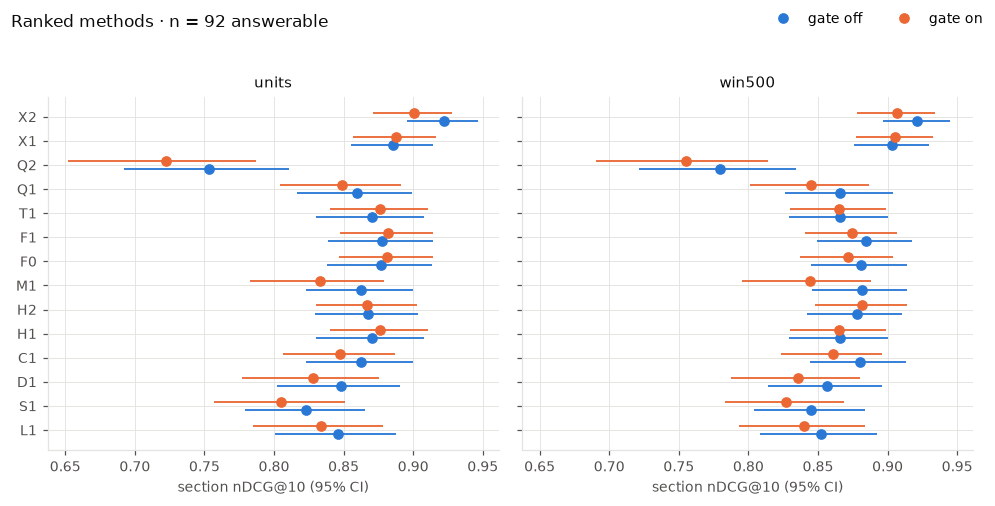

In [10]:
v1 = rt[rt["params_version"] == "v1"]
methods = [m for m in RANKED_METHODS if m in set(v1["method"])]
fig, axes = plt.subplots(1, 2, figsize=(9, 4.6), sharex=True, sharey=True)
for ax, index in zip(axes, corpus.indexes()):
    for j, (gate, label) in enumerate([(False, "gate off"), (True, "gate on")]):
        r = v1[(v1["index"] == index) & (v1["gate"] == gate) & v1["method"].isin(methods)].set_index("method").reindex(methods)
        y = np.arange(len(methods)) + (0.17 if j else -0.17)
        val = metric(r["run_id"], "section", "ndcg@10").values
        lo = metric(r["run_id"], "section", "ndcg@10", "ci_lo").values
        hi = metric(r["run_id"], "section", "ndcg@10", "ci_hi").values
        ax.hlines(y, lo, hi, color=SLOTS[j], linewidth=1.2)
        ax.plot(val, y, "o", color=SLOTS[j], label=label)
    ax.set_yticks(np.arange(len(methods)), methods)
    ax.invert_yaxis()
    ax.set_title(f"{index}")
    ax.set_xlabel("section nDCG@10 (95% CI)")
fig.suptitle("Ranked methods · n = 92 answerable", x=0.01, ha="left", color=INK)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncols=2)
fig.tight_layout(rect=(0, 0, 1, 0.95))

### RQ6: evidence recall within the budget vs context handed over (gate on, v1)

Each line is one expansion method across the 4k / 8k / 16k budgets.

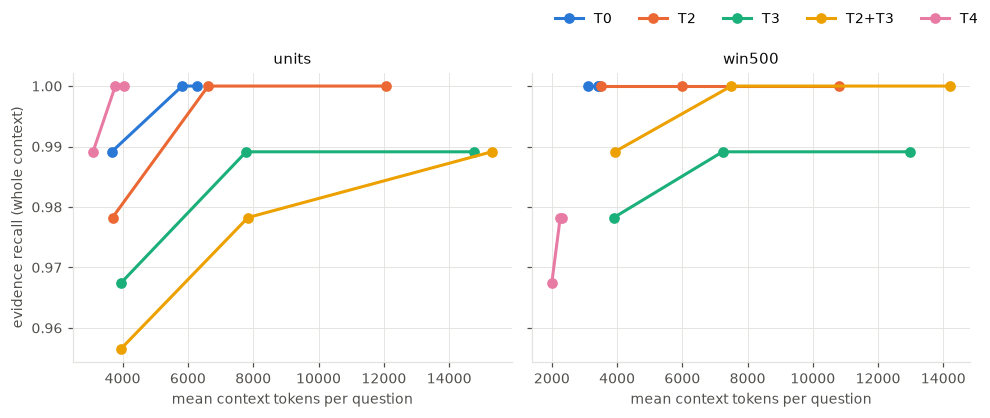

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, index in zip(axes, corpus.indexes()):
    for j, m in enumerate(EXPANSION_METHODS):
        r = v1[(v1["index"] == index) & v1["gate"] & (v1["method"] == m)].sort_values("budget")
        if r.empty:
            continue
        x = costs.set_index("run_id").loc[r["run_id"], "context_tokens"].values
        y = metric(r["run_id"], "evidence", "evidence_recall@ctx").values
        ax.plot(x, y, "-o", color=SLOTS[j], label=m)
    ax.set_title(index)
    ax.set_xlabel("mean context tokens per question")
axes[0].set_ylabel("evidence recall (whole context)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncols=5)
fig.tight_layout(rect=(0, 0, 1, 0.92))

### RQ7: windows vs units (gate off, v1)

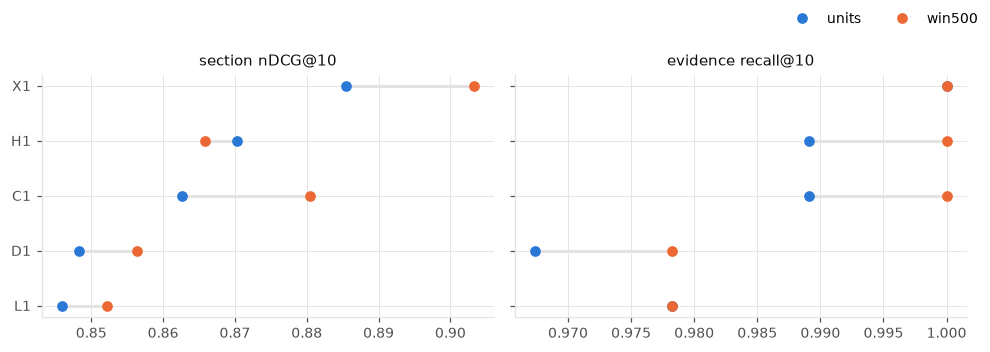

In [12]:
m7 = ["L1", "D1", "C1", "H1", "X1"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, (level, name, title) in zip(axes, [("section", "ndcg@10", "section nDCG@10"), ("evidence", "evidence_recall@10", "evidence recall@10")]):
    for j, index in enumerate(corpus.indexes()):
        r = v1[(v1["index"] == index) & ~v1["gate"] & v1["method"].isin(m7)].set_index("method").reindex(m7)
        ax.plot(metric(r["run_id"], level, name).values, np.arange(len(m7)), "o", color=SLOTS[j], label=index, zorder=3)
    u = v1[(v1["index"] == "units") & ~v1["gate"] & v1["method"].isin(m7)].set_index("method").reindex(m7)["run_id"]
    w = v1[(v1["index"] == "win500") & ~v1["gate"] & v1["method"].isin(m7)].set_index("method").reindex(m7)["run_id"]
    ax.hlines(np.arange(len(m7)), metric(u, level, name).values, metric(w, level, name).values, color=GRID, linewidth=2, zorder=2)
    ax.set_yticks(np.arange(len(m7)), m7)
    ax.invert_yaxis()
    ax.set_title(title)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncols=2)
fig.tight_layout(rect=(0, 0, 1, 0.9))

### RQ7 by gold-section length: windows minus units, section nDCG@10 (gate off, v1)

Windows should differ most from base units on long sections.

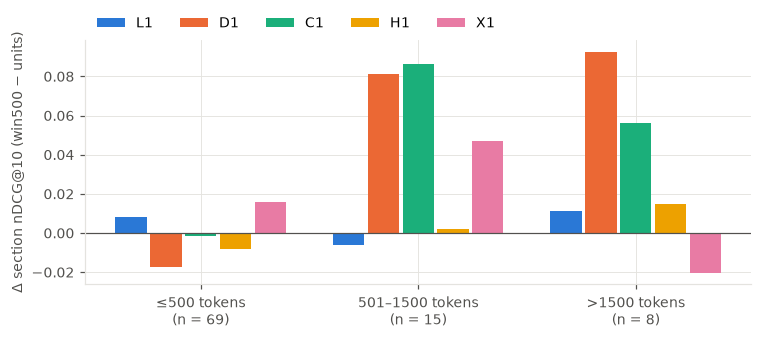

In [13]:
qf = rp._question_frame(questions, corpus).set_index("question_id")
sec = pq[(pq["level"] == "section") & (pq["metric"] == "ndcg@10")].join(qf["length_bucket"], on="question_id")
buckets = ["≤500", "501–1500", ">1500"]
fig, ax = plt.subplots(figsize=(7, 3.2))
width = 0.16
for j, m in enumerate(m7):
    d = []
    for b in buckets:
        ids = {i: v1[(v1["index"] == i) & ~v1["gate"] & (v1["method"] == m)]["run_id"] for i in corpus.indexes()}
        if any(x.empty for x in ids.values()):
            d.append(np.nan)
            continue
        s = {i: sec[(sec["run_id"] == ids[i].iloc[0]) & (sec["length_bucket"] == b)].set_index("question_id")["value"] for i in ids}
        d.append(float((s["win500"] - s["units"]).mean()))
    ax.bar(np.arange(len(buckets)) + (j - 2) * width, d, width * 0.9, color=SLOTS[j], label=m)
ax.axhline(0, color=INK2, linewidth=0.8)
ax.set_xticks(np.arange(len(buckets)), [f"{b} tokens\n(n = {int((qf['length_bucket'] == b).sum())})" for b in buckets])
ax.set_ylabel("Δ section nDCG@10 (win500 − units)")
ax.legend(ncols=5, loc="upper left", bbox_to_anchor=(0, 1.15))
fig.tight_layout()

## Gate diagnostics

Kept length and gate loss per gate position (gate A per signal, gate B after reranking), and the overall gate loss against the gate-off run of the same configuration.

In [14]:
g = gates.merge(rt[["run_id", "method", "index", "budget", "params_version"]], on="run_id")
g = g.merge(gate_overall, on="run_id", how="left")
g.sort_values(["params_version", "index", "method", "position"])[["method", "index", "budget", "position", "in_mean", "kept_mean",
                                                                  "kept_median", "gate_loss", "gate_loss_overall"]].round(3)

,method,index,budget,position,in_mean,kept_mean,kept_median,gate_loss,gate_loss_overall
0,C1,units,NaN,A:colbert,50.00,5.78,5.0,0.011,0.000
2,D1,units,NaN,A:dense,50.00,5.79,5.0,0.033,0.022
4,F0,units,NaN,A:bm25,50.00,5.59,5.0,0.033,0.000
5,F0,units,NaN,A:dense,50.00,5.83,5.0,0.033,0.000
8,F1,units,NaN,A:bm25,50.00,5.59,5.0,0.033,0.000
...,...,...,...,...,...,...,...,...,...
102,X1,win500,NaN,A:dense,50.00,6.17,5.0,0.033,0.000
103,X1,win500,NaN,B:X1,9.07,6.99,7.0,0.000,0.000
107,X2,win500,NaN,A:bm25,50.00,5.48,5.0,0.033,0.000
108,X2,win500,NaN,A:dense,50.00,6.17,5.0,0.033,0.000


## Agent decision paths (T4)

Per question: `stop` (the hits were enough), `expand`, `follow_refs`, `search`, `limit` (step limit reached).

In [15]:
rows = []
for rid in rt[rt["method"] == "T4"]["run_id"]:
    c = runs.load_config(rid)
    for s in runs.load_stats(rid):
        p = s["agent"]["path"]
        kind = "stop at once" if p == ["stop"] else ("step limit" if "limit" in p else "+".join(sorted({x for x in p if x != "stop"})))
        rows.append({"index": c["index"], "budget": c["config"]["expansion"]["budget"], "params": c["params_version"], "path": kind})
if rows:
    display(pd.DataFrame(rows).pivot_table(index="path", columns=["params", "index", "budget"], aggfunc="size", fill_value=0))

params                v1                               
index              units             win500            
budget             4096  8192  16384  4096  8192  16384
path                                                   
expand                 0     1     0      1     2     2
expand+search          3     1     0      0     0     0
follow_refs+search     0     0     0      1     0     0
search                 5     4     1      6     2     1
step limit             0     3     7      2     6     7
stop at once          92    91    92     90    90    90

## Cost per question

In [16]:
costs.merge(rt, on="run_id").groupby(["params_version", "index", "method"])[
    ["latency_qdrant_s", "latency_encoder_s", "latency_rerank_s", "latency_llm_s", "latency_total_s",
     "llm_prompt_tokens", "llm_completion_tokens", "context_tokens"]].mean().round(2)

latency_qdrant_s  latency_encoder_s  \
params_version index  method                                        
v1             units  C1                  1.87               0.03   
                      D1                  0.00               0.03   
                      F0                  0.00               0.03   
                      F1                  0.00               0.03   
                      H1                  0.01               0.03   
                      H2                  0.01               0.03   
                      L1                  0.00               0.03   
                      M1                  0.08               0.03   
                      Q1                  0.00               0.29   
                      Q2                  0.00               0.03   
                      S1                  0.00               0.03   
                      T0                  0.01               0.03   
                      T1                  0.01               0.03   
                      T2                  0.01               0.03   
                      T2+T3               0.01               0.03   
                      T3                  0.01               0.03   
                      T4                  0.01               0.08   
                      X1                  0.01               0.03   
                      X2                  0.01               0.03   
               win500 C1                  1.41               0.03   
                      D1                  0.00               0.03   
                      F0                  0.00               0.03   
                      F1                  0.00               0.03   
                      H1                  0.01               0.03   
                      H2                  0.01               0.03   
                      L1                  0.00               0.03   
                      M1                  0.22               0.03   
                      Q1                  0.00               0.29   
                      Q2                  0.00               0.03   
                      S1                  0.00               0.03   
                      T0                  0.01               0.03   
                      T1                  0.01               0.03   
                      T2                  0.01               0.03   
                      T2+T3               0.01               0.03   
                      T3                  0.01               0.03   
                      T4                  0.01               0.09   
                      X1                  0.01               0.03   
                      X2                  0.01               0.03   

                              latency_rerank_s  latency_llm_s  \
params_version index  method                                    
v1             units  C1                  0.00           0.00   
                      D1                  0.00           0.00   
                      F0                  0.00           0.00   
                      F1                  0.00           0.96   
                      H1                  0.00           0.00   
                      H2                  0.00           0.00   
                      L1                  0.00           0.00   
                      M1                  0.00           0.00   
                      Q1                  0.00          12.79   
                      Q2                  0.00           4.80   
                      S1                  0.00           0.00   
                      T0                  0.00           0.00   
                      T1                  0.00           0.00   
                      T2                  0.00           0.00   
                      T2+T3               0.00           0.00   
                      T3                  0.00           0.00   
                      T4                  0.00          14.01   
                      X1          

## Unanswerable questions (inspection only, not scored)

In [17]:
un = pd.read_excel(RESULTS / "units" / "metrics.xlsx", sheet_name="unanswerable")
un[un["run_id"].str.startswith(("H1-", "X1-", "X2-"))][["run_id", "question_id", "top5_sections", "n_distractors_in_top5", "top1_score", "n_hits"]].head(24)

,run_id,question_id,top5_sections,n_distractors_in_top5,top1_score,n_hits
64,H1-units-gateoff-v1-8415d82e,q093,AMC E 570 | CS-E 130 | AMC E 130 | CS-E 570 | ...,2,0.032787,20
65,H1-units-gateoff-v1-8415d82e,q094,CS-E 370 | AMC E 740(c)(3) | CS-E 750 | CS-E 1...,3,0.031754,20
66,H1-units-gateoff-v1-8415d82e,q095,CS-E 900 | CS-E 180 | CS-E 740 | CS-E 750 | AM...,1,0.031778,20
67,H1-units-gateoff-v1-8415d82e,q096,CS-E 1040 | CS-E 800 | CS-E 740 | AMC E 25 | C...,1,0.032787,20
68,H1-units-gateoff-v1-8415d82e,q097,AMC E 470 | AMC E 670 | CS-E 670 | AMC E 30 | ...,2,0.032266,20
69,H1-units-gateoff-v1-8415d82e,q098,AMC E 710 | CS-E 710 | AMC E 910 | CS-E 800 | ...,2,0.032522,20
70,H1-units-gateoff-v1-8415d82e,q099,CS-E 10 | AMC E 80 | AMC E 170 | CS-E 1000 | A...,1,0.032787,20
71,H1-units-gateoff-v1-8415d82e,q100,CS-E 300 | CS-E 260 | CS-E 920 | AMC E 40(d) |...,2,0.032522,20
72,H1-units-gateon-v1-9f5e5fd2,q093,AMC E 570 | CS-E 130 | CS-E 570 | CS-E 25 | CS...,2,0.032787,8
73,H1-units-gateon-v1-9f5e5fd2,q094,CS-E 370 | CS-E 750 | AMC E 740(c)(3) | AMC E ...,3,0.031754,15


## Pipeline diagrams

Picked by hand for the write-up (here: one per RQ). Each is generated from the run's stored config and written to `results/diagrams/<run_id>.md`.

In [18]:
def pick(method, index, gate, budget=None, params_version="v1"):
    r = rt[(rt["method"] == method) & (rt["index"] == index) & (rt["gate"] == gate) & (rt["params_version"] == params_version)]
    if budget is not None:
        r = r[r["budget"] == budget]
    return r["run_id"].iloc[0] if len(r) else None

DIAGRAM_RUNS = [x for x in [
    pick("C1", "units", False),            # RQ1
    pick("H1", "units", True),             # RQ2
    pick("X2", "units", True),             # RQ3
    pick("Q1", "units", False),            # RQ4
    pick("F1", "units", True),             # RQ5
    pick("T4", "units", True, 16384),      # RQ6
    pick("H1", "win500", False),           # RQ7
] if x]
for rid in DIAGRAM_RUNS:
    path = rp.write_diagram(rid, RESULTS / "diagrams", rm=rm, sig=pd.concat([sig, sig7]), gates=gates, costs=costs)
    display(Markdown(path.read_text(encoding="utf-8")))

# C1-units-gateoff-v1-b814c18d

C1: ColBERT MaxSim over all units · index `units` · gate off · params `v1` · config `b814c18d8312`

```mermaid
flowchart LR
  Q(["question"])
  IX[("cse_units_v1<br/>base units")]
  Q --> IX
  S0["ColBERT MaxSim<br/>client, exact<br/>top-50"]
  IX --> S0
  CTX(["final context<br/>k ≤ 20"])
  S0 --> CTX
  subgraph M["metrics"]
    MP["section nDCG@10 0.863 [0.823, 0.900]<br/>Recall@10 0.989<br/>evidence recall@10 0.989<br/>latency 1.90 s/question<br/>n = 92 answerable"]
  end
  CTX -.- MP
```

| comparison | Δ section nDCG@10 | 95% CI | p (Holm) |
|---|---|---|---|
| RQ1 C1 vs L1 | +0.017 | [-0.027, +0.061] | 1.0000 |
| RQ7 C1@win500 vs C1@units | +0.018 | [-0.002, +0.041] | 0.4644 |


# H1-units-gateon-v1-9f5e5fd2

H1: BM25 + dense, RRF · index `units` · gate on · params `v1` · config `9f5e5fd2f264`

```mermaid
flowchart LR
  Q(["question"])
  IX[("cse_units_v1<br/>base units")]
  Q --> IX
  S0["BM25<br/>top-50"]
  IX --> S0
  GA0{"gate A<br/>τ 0.4 δ 0.3<br/>keep 5–50"}
  S0 --> GA0
  S1["bge-m3 dense<br/>top-50"]
  IX --> S1
  GA1{"gate A<br/>τ 0.4 δ 0.3<br/>keep 5–50"}
  S1 --> GA1
  FU["RRF<br/>k = 60"]
  GA0 --> FU
  GA1 --> FU
  CTX(["final context<br/>k ≤ 20"])
  FU --> CTX
  subgraph M["metrics"]
    MP["section nDCG@10 0.876 [0.840, 0.911]<br/>Recall@10 1.000<br/>evidence recall@10 1.000<br/>kept length 5.7 · gate loss 0.033<br/>latency 0.04 s/question<br/>n = 92 answerable"]
  end
  CTX -.- MP
```

| comparison | Δ section nDCG@10 | 95% CI | p (Holm) |
|---|---|---|---|
| RQ2 H1 vs L1 | +0.043 | [+0.012, +0.076] | 0.0672 |
| RQ2 H1 vs D1 | +0.048 | [+0.015, +0.085] | 0.0672 |
| RQ2 H2 vs H1 | -0.009 | [-0.024, +0.004] | 0.9434 |
| RQ3 X1 vs H1 | +0.011 | [-0.015, +0.039] | 0.6897 |
| RQ3 X2 vs H1 | +0.024 | [-0.000, +0.050] | 0.2584 |
| RQ5 F1 vs H1 | +0.005 | [-0.007, +0.018] | 1.0000 |
| RQ5 T1 vs H1 | +0.000 | [+0.000, +0.000] | 1.0000 |


# X2-units-gateon-v1-b3ace7ee

X2: H1 -> jina-reranker-v3 · index `units` · gate on · params `v1` · config `b3ace7eea425`

```mermaid
flowchart LR
  Q(["question"])
  IX[("cse_units_v1<br/>base units")]
  Q --> IX
  S0["BM25<br/>top-50"]
  IX --> S0
  GA0{"gate A<br/>τ 0.4 δ 0.3<br/>keep 5–50"}
  S0 --> GA0
  S1["bge-m3 dense<br/>top-50"]
  IX --> S1
  GA1{"gate A<br/>τ 0.4 δ 0.3<br/>keep 5–50"}
  S1 --> GA1
  FU["RRF<br/>k = 60"]
  GA0 --> FU
  GA1 --> FU
  RR["X2 jina-reranker-v3<br/>top 50 in"]
  FU --> RR
  GB{"gate B<br/>τ 0.2 δ 0.5<br/>keep 5–20"}
  RR --> GB
  CTX(["final context<br/>k ≤ 20"])
  GB --> CTX
  subgraph M["metrics"]
    MP["section nDCG@10 0.900 [0.871, 0.928]<br/>Recall@10 1.000<br/>evidence recall@10 1.000<br/>kept length 6.2 · gate loss 0.033<br/>latency 1.35 s/question<br/>n = 92 answerable"]
  end
  CTX -.- MP
```

| comparison | Δ section nDCG@10 | 95% CI | p (Holm) |
|---|---|---|---|
| RQ3 X2 vs H1 | +0.024 | [-0.000, +0.050] | 0.2584 |
| RQ3 X1 vs X2 | -0.013 | [-0.027, +0.000] | 0.2584 |


# Q1-units-gateoff-v1-73502117

Q1: HyDE (dense) · index `units` · gate off · params `v1` · config `73502117bcc2`

```mermaid
flowchart LR
  Q(["question"])
  QT["Q1 HyDE<br/>Qwen, 1 passage,<br/>mean with question"]
  Q --> QT
  IX[("cse_units_v1<br/>base units")]
  QT --> IX
  S0["bge-m3 dense<br/>top-50"]
  IX --> S0
  CTX(["final context<br/>k ≤ 20"])
  S0 --> CTX
  subgraph M["metrics"]
    MP["section nDCG@10 0.860 [0.817, 0.899]<br/>Recall@10 0.989<br/>evidence recall@10 0.978<br/>latency 13.08 s/question<br/>n = 92 answerable"]
  end
  CTX -.- MP
```

| comparison | Δ section nDCG@10 | 95% CI | p (Holm) |
|---|---|---|---|
| RQ4 Q1 vs D1 | +0.011 | [-0.013, +0.039] | 0.4027 |


# F1-units-gateon-v1-d85f1376

F1: H1 + LLM-extracted engine-type filter · index `units` · gate on · params `v1` · config `d85f1376506a`

```mermaid
flowchart LR
  Q(["question"])
  FL{"filter<br/>engine_type ∈ {x, all}<br/>Qwen JSON"}
  Q --> FL
  IX[("cse_units_v1<br/>base units")]
  FL --> IX
  S0["BM25<br/>top-50"]
  IX --> S0
  GA0{"gate A<br/>τ 0.4 δ 0.3<br/>keep 5–50"}
  S0 --> GA0
  S1["bge-m3 dense<br/>top-50"]
  IX --> S1
  GA1{"gate A<br/>τ 0.4 δ 0.3<br/>keep 5–50"}
  S1 --> GA1
  FU["RRF<br/>k = 60"]
  GA0 --> FU
  GA1 --> FU
  CTX(["final context<br/>k ≤ 20"])
  FU --> CTX
  subgraph M["metrics"]
    MP["section nDCG@10 0.882 [0.847, 0.915]<br/>Recall@10 1.000<br/>evidence recall@10 1.000<br/>kept length 5.7 · gate loss 0.033<br/>latency 0.99 s/question<br/>n = 92 answerable"]
  end
  CTX -.- MP
```

| comparison | Δ section nDCG@10 | 95% CI | p (Holm) |
|---|---|---|---|
| RQ5 F1 vs H1 | +0.005 | [-0.007, +0.018] | 1.0000 |


# T4-b16k-units-gateon-v1-f395387b

T4: H1 -> agentic small-to-big · index `units` · gate on · params `v1` · config `f395387b14d4`

```mermaid
flowchart LR
  Q(["question"])
  IX[("cse_units_v1<br/>base units")]
  Q --> IX
  S0["BM25<br/>top-50"]
  IX --> S0
  GA0{"gate A<br/>τ 0.4 δ 0.3<br/>keep 5–50"}
  S0 --> GA0
  S1["bge-m3 dense<br/>top-50"]
  IX --> S1
  GA1{"gate A<br/>τ 0.4 δ 0.3<br/>keep 5–50"}
  S1 --> GA1
  FU["RRF<br/>k = 60"]
  GA0 --> FU
  GA1 --> FU
  EX["T4 agent<br/>≤5 steps, budget 16384<br/>expand · follow_refs · search · done"]
  FU --> EX
  CTX(["final context<br/>budgeted"])
  EX --> CTX
  subgraph M["metrics"]
    MP["section nDCG@10 0.913 [0.886, 0.938]<br/>Recall@10 1.000<br/>evidence recall@10 1.000<br/>kept length 5.7 · gate loss 0.033<br/>latency 15.38 s/question<br/>n = 92 answerable"]
  end
  CTX -.- MP
```

| comparison | Δ section nDCG@10 | 95% CI | p (Holm) |
|---|---|---|---|
| RQ6 T4 vs T2+T3 | -0.001 | [-0.039, +0.040] | 1.0000 |


# H1-win500-gateoff-v1-9d5dfb15

H1: BM25 + dense, RRF · index `win500` · gate off · params `v1` · config `9d5dfb150d1e`

```mermaid
flowchart LR
  Q(["question"])
  IX[("cse_win500_v1<br/>500-token windows")]
  Q --> IX
  S0["BM25<br/>top-50"]
  IX --> S0
  S1["bge-m3 dense<br/>top-50"]
  IX --> S1
  FU["RRF<br/>k = 60"]
  S0 --> FU
  S1 --> FU
  CTX(["final context<br/>k ≤ 20"])
  FU --> CTX
  subgraph M["metrics"]
    MP["section nDCG@10 0.866 [0.829, 0.900]<br/>Recall@10 1.000<br/>evidence recall@10 1.000<br/>latency 0.04 s/question<br/>n = 92 answerable"]
  end
  CTX -.- MP
```

| comparison | Δ section nDCG@10 | 95% CI | p (Holm) |
|---|---|---|---|
| RQ2 H1 vs L1 | +0.014 | [-0.009, +0.038] | 0.8423 |
| RQ2 H1 vs D1 | +0.009 | [-0.018, +0.037] | 0.8423 |
| RQ2 H2 vs H1 | +0.012 | [-0.003, +0.027] | 0.5297 |
| RQ3 X1 vs H1 | +0.037 | [+0.013, +0.065] | 0.0129 |
| RQ3 X2 vs H1 | +0.056 | [+0.026, +0.087] | 0.0012 |
| RQ5 F1 vs H1 | +0.019 | [+0.009, +0.031] | 0.0008 |
| RQ5 T1 vs H1 | +0.000 | [+0.000, +0.000] | 1.0000 |
| RQ7 H1@win500 vs H1@units | -0.004 | [-0.025, +0.017] | 1.0000 |


## Output checks (plan 8)

* both `metrics.csv` / `metrics.xlsx` pairs and `granularity.csv` match `run_metrics.parquet` (same run count and values);
* each CSV opens cleanly: UTF-8, one header row;
* the `unanswerable` sheet lists all 8 questions for every run;
* each diagram's stage list matches its run's `config.json`.

In [19]:
nd = rm[(rm["subset"] == "all") & (rm["level"] == "section") & (rm["metric"] == "ndcg@10")].set_index("run_id")["value"]
for index in corpus.indexes():
    t = pd.read_csv(RESULTS / index / "metrics.csv", encoding="utf-8")
    assert len(t) == (rt["index"] == index).sum(), "run count differs"
    assert np.allclose(t.set_index("run_id")["section_ndcg@10"], nd.reindex(t["run_id"]).values, equal_nan=True)
    with open(RESULTS / index / "metrics.csv", encoding="utf-8") as f:
        header = f.readline()
        assert "run_id" in header and all("run_id" not in ln for ln in f), "more than one header row"
    x = pd.ExcelFile(RESULTS / index / "metrics.xlsx")
    assert {"metrics", "by_question_type", "by_engine_type", "by_kind", "mentions_section_id", "length_bucket",
            "significance", "gate", "per_question", "unanswerable"} <= set(x.sheet_names)
    xm = pd.read_excel(x, "metrics")
    assert np.allclose(xm.set_index("run_id")["section_ndcg@10"], nd.reindex(xm["run_id"]).values, equal_nan=True)
    un = pd.read_excel(x, "unanswerable")
    assert un.groupby("run_id")["question_id"].nunique().eq(8).all() and un["run_id"].nunique() == len(t)
g7 = pd.read_csv(RESULTS / "granularity.csv")
assert len(g7) == len(sig7)
assert all(rp.diagram_matches_config(r) for r in DIAGRAM_RUNS)
print("output checks passed")

output checks passed
